# 🧬 GenIVF-RAG v8 — Real-Data Pipeline (Mendeley Embryo Dataset)

**What changed from v7 (read this first)**

| Issue in v7 | Fix in v8 |
|---|---|
| Mendeley loader matched **no** columns (they are in Chinese) → every variable, including the outcome, was synthesized | Explicit Chinese → English column map; **no synthetic variables anywhere** |
| Downstream cells (split, KB, metrics, Table 13) still ran on the 1,000-patient synthetic generator | Single pipeline, real data only |
| 2,542 rows treated as cycles; rows are **embryos** from 1,415 patients with identical features/labels → train/test leakage | Collapsed to one row per patient; patient-level split |
| Outcome called *live birth* | Dataset label is **clinical pregnancy** (transfer-level) |
| Protocol accuracy / DAS scored against synthetic ESHRE-sampled labels (circular) | Protocol recommendation evaluated on the one real protocol variable: **Gn stimulation duration (days)** |
| GPT-4o failed (HTTP 429) and silently fell back to a Python stub | LLM step logs the backend for every patient and **refuses to report results** if any call fell back |
| Faithfulness = keyword-overlap proxy; retrieval "expert" relevance = age+diagnosis match | Deterministic, clearly named grounding checks; retrieval evaluated with objective similarity + outcome concordance |

**Dataset:** Wang M. (2026), *Embryo dataset*, Mendeley Data v1, doi:10.17632/x5s3ky9cpv.1 (CC BY 4.0; Gansu Provincial Maternity and Child-care Hospital, 2016–2020) — `Embryo dataset_2542.xlsx`.
Variables available: female age, basal FSH/PRL/T/P, AMH, female blood/coagulation/thyroid/metabolic labs, male semen analysis + labs,
Gn duration, HCG-day progesterone, post-processing semen parameters, number of embryos frozen, and the pregnancy label.
**Not available:** BMI, AFC, LH, E2, infertility diagnosis, protocol type, starting dose, trigger, transfer type, OHSS, live birth, cycle year.

## ⚙️ Step 0 — Setup

In [1]:
# On Colab, uncomment the next line once:
# !pip install -q pandas openpyxl scikit-learn matplotlib rank_bm25 openai

import os, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from rank_bm25 import BM25Okapi
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
print('✅ Imports complete.')

✅ Imports complete.


## 🔧 Step 1 — Configuration

In [2]:
RANDOM_STATE = 42
TEST_SIZE    = 0.20       # patient-level hold-out
TOP_K        = 10         # retrieved cases per query (chosen on train CV below, not on test)
N_BOOT       = 1000       # bootstrap resamples for 95% CIs

DATA_CANDIDATES = [
    '/content/Embryo dataset_2542.xlsx', '/content/Embryo_dataset_2542.xlsx',
    '../Datasets/Embryo dataset_2542.xlsx', 'Embryo dataset_2542.xlsx',
]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)
assert DATA_PATH, f'Dataset not found. Upload it or edit DATA_CANDIDATES: {DATA_CANDIDATES}'

OUTPUT_DIR = '/content/genivf_outputs_v8' if os.path.exists('/content') else 'genivf_outputs_v8'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── LLM settings (Step 9). 'none' skips the LLM step and reports nothing for it.
#    'openai' uses OPENAI_API_KEY; 'openai_compatible' works with Ollama / Groq / Together etc.
LLM_PROVIDER = os.environ.get('GENIVF_LLM_PROVIDER', 'none')   # 'none' | 'openai' | 'openai_compatible'
LLM_MODEL    = os.environ.get('GENIVF_LLM_MODEL', 'gpt-4o')
LLM_BASE_URL = os.environ.get('GENIVF_LLM_BASE_URL', '')       # e.g. 'http://localhost:11434/v1' for Ollama
LLM_N_EVAL   = None       # None = all test patients

print('Data      :', DATA_PATH)
print('Outputs   :', OUTPUT_DIR)
print('LLM       :', LLM_PROVIDER, LLM_MODEL if LLM_PROVIDER != 'none' else '')

Data      : ../Datasets/Embryo dataset_2542.xlsx
Outputs   : genivf_outputs_v8
LLM       : openai_compatible llama3.1:8b


## 📥 Step 2 — Load, translate columns, collapse embryos → patients

In [3]:
COLUMN_MAP = {
    '胚胎': 'embryo_id', 'label': 'pregnancy',
    '女方年龄': 'f_age', '女方基础FSH': 'f_basal_fsh', '女方基础PRL': 'f_basal_prl',
    '女方基础T': 'f_basal_t', '女方基础P': 'f_basal_p', '女方AMH': 'f_amh',
    '女方白细胞计数': 'f_wbc', '女方血小板': 'f_platelets', '女方血细胞压积': 'f_hct',
    '女方凝血常规PT': 'f_pt', '女方凝血常规APPT': 'f_aptt', '女方凝血常规TT': 'f_tt',
    '女方D二聚体': 'f_d_dimer', '女方甲功TPO': 'f_tpo_ab', '女方空腹血糖': 'f_glucose',
    '女方肾功尿酸': 'f_uric_acid',
    '男方浓度': 'm_sperm_conc', '男方正常形态率': 'm_normal_morph', '男方PR': 'm_pr',
    '男方NP': 'm_np', '男方存活率': 'm_vitality', '男方DFI': 'm_dfi', '男方ALT': 'm_alt',
    '男方AST': 'm_ast', '男方血肌酐': 'm_creatinine', '男方白细胞': 'm_wbc',
    '男方血小板': 'm_platelets', '男方空腹血糖': 'm_glucose',
    '女方用药Gn总天数': 'gn_days', '女方用药HCG日P': 'hcg_day_p',
    '男方精液处理后NP': 'm_post_np', '男方精液处理方法': 'm_prep_method',
    '男方精液处理后密度': 'm_post_density', '男方精液处理后PR': 'm_post_pr',
    '男方精液处理后IM': 'm_post_im', '胚胎冷冻数': 'embryos_frozen',
}

raw = pd.read_excel(DATA_PATH)
missing = set(COLUMN_MAP) - set(raw.columns)
assert not missing, f'Unexpected file layout, missing columns: {missing}'
emb = raw.rename(columns=COLUMN_MAP)
emb['patient_id'] = emb['embryo_id'].astype(str).str.split('_').str[0]

feat_cols = [c for c in emb.columns if c not in ('embryo_id', 'patient_id')]
per_pt_unique = emb.groupby('patient_id')[feat_cols].nunique().max(axis=1)
assert (per_pt_unique == 1).all(), 'Some patients have differing features/labels across embryo rows'

df = emb.groupby('patient_id', as_index=False).first().drop(columns='embryo_id')
df['n_embryo_rows'] = emb.groupby('patient_id').size().values

print(f'Embryo rows : {len(emb):,}')
print(f'Patients    : {len(df):,}  (rows per patient: {emb.groupby("patient_id").size().value_counts().sort_index().to_dict()})')
print(f'Every patient has identical features and label across embryo rows → unit of analysis = patient/transfer.')
print(f'Clinical pregnancy rate: {df.pregnancy.mean():.1%}')

Embryo rows : 2,542
Patients    : 1,415  (rows per patient: {1: 345, 2: 1013, 3: 57})
Every patient has identical features and label across embryo rows → unit of analysis = patient/transfer.
Clinical pregnancy rate: 39.2%


## 🧹 Step 3 — Plausibility cleaning
Values outside physiologically plausible ranges are data-entry errors (e.g. haematocrit 149 %, sperm vitality 474 %).
They are set to missing and imputed (median, fitted on the training set only).

In [4]:
PLAUSIBLE = {
    'f_basal_fsh': (0.5, 40), 'f_basal_prl': (1, 200), 'f_basal_t': (0, 5), 'f_basal_p': (0, 30),
    'f_amh': (0.01, 30), 'f_hct': (20, 60), 'f_pt': (8, 20), 'f_aptt': (15, 60), 'f_tt': (10, 30),
    'm_normal_morph': (0, 100), 'm_pr': (0, 100), 'm_np': (0, 100), 'm_vitality': (0, 100),
    'm_dfi': (0, 100), 'm_alt': (0, 500), 'm_ast': (0, 500), 'm_creatinine': (20, 200),
    'm_platelets': (50, 600),
}
cleaned = {}
for col, (lo, hi) in PLAUSIBLE.items():
    bad = ~df[col].between(lo, hi)
    cleaned[col] = int(bad.sum())
    df.loc[bad, col] = np.nan
print('Values set to missing (implausible):')
print({k: v for k, v in cleaned.items() if v})
print(f'Total: {sum(cleaned.values())} values in {len(df)} patients')

Values set to missing (implausible):
{'f_basal_fsh': 4, 'f_basal_prl': 1, 'f_basal_t': 6, 'f_basal_p': 9, 'f_amh': 2, 'f_hct': 7, 'f_pt': 2, 'f_aptt': 4, 'f_tt': 11, 'm_np': 2, 'm_vitality': 3, 'm_alt': 2, 'm_ast': 1, 'm_creatinine': 303, 'm_platelets': 3}
Total: 360 values in 1415 patients


## 🚨 Step 3b — Label leakage in the published file: class-specific imputed constants
The file is sorted by outcome (all non-pregnant patients first), and in several columns missing values were filled with a
**different constant for each outcome class** (e.g. prepared-semen IM = 9.44 only in non-pregnant patients, 9.48 only in pregnant; fasting glucose 5.05 in 195 non-pregnant vs 4 pregnant, 5.04 in 144 pregnant vs 10 non-pregnant).
A tree model can read the label straight from these constants, which inflates AUROC to ~0.86 and probably explains the unreplicated GitHub result.

Fix: on the **training split only**, find non-integer values that occur ≥ 10 times with a class split wildly inconsistent with the base rate (exact binomial test, p < 10⁻⁶); treat those values as missing everywhere,
then impute with the label-blind training median. The before/after AUROC is reported in Step 5.

In [5]:
def find_class_constants(frame, cols, min_count=10, alpha=1e-6):
    # A repeated non-integer value whose class split is wildly inconsistent with the base rate is an imputed class
    # constant (two-sided exact binomial test, p < 1e-6). Genuine repeated lab values follow the ~39/61 base rate.
    from scipy.stats import binomtest
    base = frame[TARGET].mean()
    found = []
    for c in cols:
        vc = frame.groupby([c, TARGET]).size().unstack(fill_value=0)
        for v, r in vc.iterrows():
            n0, n1 = int(r.get(0, 0)), int(r.get(1, 0))
            if float(v).is_integer() or n0 + n1 < min_count:   # imputed means are never whole numbers
                continue
            pval = binomtest(n1, n0 + n1, base).pvalue
            if pval < alpha:
                found.append({'column': c, 'value': v, 'mostly_in': 'pregnant' if n1 / (n0 + n1) > base else 'non-pregnant',
                              'n_non_preg_train': n0, 'n_preg_train': n1, 'binomial_p': pval})
    return pd.DataFrame(found)

def mask_constants(frame, consts):
    out = frame.copy()
    for c, v in zip(consts.column, consts.value):
        out.loc[np.isclose(out[c], v), c] = np.nan
    return out

## 🧩 Step 4 — Feature sets and patient-level split
* **BASELINE** – known before stimulation (female + male baseline labs). Used for retrieval and recommendation.
* **CYCLE** – known during the cycle (Gn days, HCG-day P, prepared-semen parameters).
* `embryos_frozen` is a post-retrieval embryology outcome and is excluded from all models (reported separately as a sensitivity check).

In [6]:
BASELINE = ['f_age', 'f_basal_fsh', 'f_basal_prl', 'f_basal_t', 'f_basal_p', 'f_amh',
            'f_wbc', 'f_platelets', 'f_hct', 'f_pt', 'f_aptt', 'f_tt', 'f_d_dimer', 'f_tpo_ab',
            'f_glucose', 'f_uric_acid', 'm_sperm_conc', 'm_normal_morph', 'm_pr', 'm_np',
            'm_vitality', 'm_dfi', 'm_alt', 'm_ast', 'm_creatinine', 'm_wbc', 'm_platelets', 'm_glucose']
CYCLE    = ['gn_days', 'hcg_day_p', 'm_post_np', 'm_prep_method', 'm_post_density', 'm_post_pr', 'm_post_im']
TARGET   = 'pregnancy'
SKEWED   = ['f_basal_prl', 'f_basal_t', 'f_basal_p', 'f_amh', 'f_d_dimer', 'f_tpo_ab',
            'm_sperm_conc', 'm_alt', 'm_ast']

train, test = train_test_split(df, test_size=TEST_SIZE, stratify=df[TARGET], random_state=RANDOM_STATE)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
assert not set(train.patient_id) & set(test.patient_id)

# Keep untouched copies to quantify the leakage effect in Step 5
train_leaky, test_leaky = train.copy(), test.copy()
CLASS_CONSTANTS = find_class_constants(train, BASELINE + CYCLE)
CLASS_CONSTANTS.to_csv(f'{OUTPUT_DIR}/table_class_specific_constants.csv', index=False)
train, test = mask_constants(train, CLASS_CONSTANTS), mask_constants(test, CLASS_CONSTANTS)
hit = np.zeros(len(df), bool)
for c, v in zip(CLASS_CONSTANTS.column, CLASS_CONSTANTS.value): hit |= np.isclose(df[c], v)
n_masked = int(sum(np.isclose(df[c], v).sum() for c, v in zip(CLASS_CONSTANTS.column, CLASS_CONSTANTS.value)))
n_pt_affected = int(hit.sum())
print(f'Class-specific constants found on train: {len(CLASS_CONSTANTS)} values in {CLASS_CONSTANTS.column.nunique()} columns '
      f'→ {n_masked} cells set to missing; {n_pt_affected} of {len(df)} patients carry ≥1 such value')
print(CLASS_CONSTANTS.to_string(index=False))

def prep(frame, cols):
    X = frame[cols].copy()
    for c in SKEWED:
        if c in X: X[c] = np.log1p(X[c])
    return X

imp = SimpleImputer(strategy='median').fit(prep(train, BASELINE + CYCLE))
def matrix(frame, cols):
    full = pd.DataFrame(imp.transform(prep(frame, BASELINE + CYCLE)), columns=BASELINE + CYCLE)
    return full[cols].values

y_tr, y_te = train[TARGET].values, test[TARGET].values
print(f'Train: {len(train)} patients (pregnancy {y_tr.mean():.1%}) | Test: {len(test)} patients (pregnancy {y_te.mean():.1%})')

char = pd.DataFrame({
    'Train median [IQR]': train[['f_age','f_amh','f_basal_fsh','gn_days','hcg_day_p']].apply(
        lambda s: f'{s.median():.2f} [{s.quantile(.25):.2f}–{s.quantile(.75):.2f}]'),
    'Test median [IQR]': test[['f_age','f_amh','f_basal_fsh','gn_days','hcg_day_p']].apply(
        lambda s: f'{s.median():.2f} [{s.quantile(.25):.2f}–{s.quantile(.75):.2f}]'),
})
char.to_csv(f'{OUTPUT_DIR}/table_cohort.csv')
char

Class-specific constants found on train: 25 values in 13 columns → 2382 cells set to missing; 836 of 1415 patients carry ≥1 such value
        column  value    mostly_in  n_non_preg_train  n_preg_train   binomial_p
   f_basal_fsh   6.54     pregnant                 0            26 2.703648e-11
   f_basal_fsh   6.64 non-pregnant                38             0 7.827752e-09
   f_basal_prl  17.64 non-pregnant                34             0 8.643729e-08
   f_basal_prl  17.98     pregnant                 0            22 1.142363e-09
     f_basal_p   1.39 non-pregnant               116             0 9.739676e-26
     f_basal_p   1.48     pregnant                 0            92 4.030528e-38
         f_amh   3.11 non-pregnant                48             1 1.032269e-09
         f_amh   3.39     pregnant                 2            33 8.814162e-12
     f_d_dimer   0.20     pregnant                16            95 8.686709e-24
     f_d_dimer   0.21 non-pregnant               129             

,Train median [IQR],Test median [IQR]
f_age,30.00 [28.00–33.00],30.00 [27.00–33.00]
f_amh,2.60 [1.37–4.52],2.65 [1.38–5.03]
f_basal_fsh,6.50 [5.30–7.80],6.40 [5.22–7.80]
gn_days,10.00 [9.00–11.00],10.00 [9.00–11.00]
hcg_day_p,0.67 [0.44–0.90],0.68 [0.48–0.92]


## 📈 Step 5 — Outcome prediction (clinical pregnancy): ML baselines

In [7]:
rng_boot = np.random.default_rng(RANDOM_STATE)
BOOT_IDX = [rng_boot.integers(0, len(y_te), len(y_te)) for _ in range(N_BOOT)]

def boot_ci(metric, y, p):
    vals = [metric(y[i], p[i]) for i in BOOT_IDX if len(np.unique(y[i])) == 2]
    return np.percentile(vals, [2.5, 97.5])

MODELS = {
    'Logistic Regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)),
    'Random Forest':       lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    'HistGBM':             lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
}
FEATURE_SETS = {'Baseline': BASELINE, 'Baseline + cycle': BASELINE + CYCLE}

rows, test_probs = [], {}
for fs_name, cols in FEATURE_SETS.items():
    Xtr, Xte = matrix(train, cols), matrix(test, cols)
    for m_name, make in MODELS.items():
        clf = make().fit(Xtr, y_tr)
        p = clf.predict_proba(Xte)[:, 1]
        lo, hi = boot_ci(roc_auc_score, y_te, p)
        cv = cross_val_predict(make(), Xtr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method='predict_proba')[:, 1]
        rows.append({'Features': fs_name, 'Model': m_name,
                     'Train 5-fold CV AUROC': round(roc_auc_score(y_tr, cv), 4),
                     'Test AUROC': round(roc_auc_score(y_te, p), 4), '95% CI': f'[{lo:.3f}, {hi:.3f}]',
                     'Test AUPRC': round(average_precision_score(y_te, p), 4),
                     'Test Brier': round(brier_score_loss(y_te, p), 4)})
        test_probs[(fs_name, m_name)] = p
tbl_ml = pd.DataFrame(rows)
tbl_ml.to_csv(f'{OUTPUT_DIR}/table_outcome_ml.csv', index=False)

# ── Leakage check: same models on the raw file (class-specific constants left in place) ──
imp_leaky = SimpleImputer(strategy='median').fit(prep(train_leaky, BASELINE + CYCLE))
mat_leaky = lambda f, cols: pd.DataFrame(imp_leaky.transform(prep(f, BASELINE + CYCLE)), columns=BASELINE + CYCLE)[cols].values
leak_rows = []
for fs_name, cols in FEATURE_SETS.items():
    for m_name in ['Logistic Regression', 'HistGBM']:
        p = MODELS[m_name]().fit(mat_leaky(train_leaky, cols), y_tr).predict_proba(mat_leaky(test_leaky, cols))[:, 1]
        clean = tbl_ml[(tbl_ml.Features == fs_name) & (tbl_ml.Model == m_name)]['Test AUROC'].iloc[0]
        leak_rows.append({'Features': fs_name, 'Model': m_name, 'AUROC raw file (leaky)': round(roc_auc_score(y_te, p), 4),
                          'AUROC after masking': clean})
tbl_leak = pd.DataFrame(leak_rows)
tbl_leak.to_csv(f'{OUTPUT_DIR}/table_leakage_effect.csv', index=False)
# Permutation importance of the leakage-free gradient-boosting model (test set)
from sklearn.inspection import permutation_importance
hgb_clean_model = MODELS['HistGBM']().fit(matrix(train, BASELINE), y_tr)
_pi = permutation_importance(hgb_clean_model, matrix(test, BASELINE), y_te, scoring='roc_auc', n_repeats=20, random_state=RANDOM_STATE)
tbl_imp = pd.DataFrame({'feature': BASELINE, 'auroc_drop_mean': _pi.importances_mean, 'auroc_drop_sd': _pi.importances_std}) \
            .sort_values('auroc_drop_mean', ascending=False).reset_index(drop=True)
tbl_imp.to_csv(f'{OUTPUT_DIR}/table_permutation_importance.csv', index=False)
print('Top permutation importances (leakage-free gradient boosting, test AUROC drop):')
print(tbl_imp.head(5).round(4).to_string(index=False)); print()
print('Effect of class-specific constants on test AUROC:')
print(tbl_leak.to_string(index=False))
print(f'\nPrevalence (AUPRC of a random model): {y_te.mean():.3f}')
tbl_ml

Top permutation importances (leakage-free gradient boosting, test AUROC drop):
     feature  auroc_drop_mean  auroc_drop_sd
       f_age           0.0388         0.0141
       f_amh           0.0277         0.0181
 f_uric_acid           0.0223         0.0073
m_sperm_conc           0.0152         0.0087
       m_alt           0.0123         0.0045

Effect of class-specific constants on test AUROC:
        Features               Model  AUROC raw file (leaky)  AUROC after masking
        Baseline Logistic Regression                  0.5883               0.5823
        Baseline             HistGBM                  0.8579               0.6214
Baseline + cycle Logistic Regression                  0.5664               0.5605
Baseline + cycle             HistGBM                  0.8864               0.6095

Prevalence (AUPRC of a random model): 0.392


,Features,Model,Train 5-fold CV AUROC,Test AUROC,95% CI,Test AUPRC,Test Brier
0,Baseline,Logistic Regression,0.5747,0.5823,"[0.515, 0.648]",0.4667,0.2349
1,Baseline,Random Forest,0.5628,0.5975,"[0.533, 0.660]",0.4475,0.2320
2,Baseline,HistGBM,0.5624,0.6214,"[0.558, 0.684]",0.4728,0.2308
3,Baseline + cycle,Logistic Regression,0.5964,0.5605,"[0.493, 0.623]",0.4306,0.2446
4,Baseline + cycle,Random Forest,0.5817,0.6043,"[0.539, 0.667]",0.4460,0.2311
5,Baseline + cycle,HistGBM,0.5801,0.6095,"[0.548, 0.671]",0.4548,0.2344


## 🔍 Step 6 — Retrieval knowledge base (training patients only)
* **Dense (structured):** cosine similarity on standardized baseline features.
* **Sparse:** BM25 over a verbalized, discretized case description (e.g. `age_30_34 amh_high fsh_normal`).
* **Hybrid:** Reciprocal Rank Fusion (k=60) of the two rankings.
* **Contrastive split:** separate indices for pregnant (positive) and non-pregnant (negative) cases.

In [8]:
scaler_ret = StandardScaler().fit(matrix(train, BASELINE))
Z_tr = scaler_ret.transform(matrix(train, BASELINE))
Z_te = scaler_ret.transform(matrix(test, BASELINE))
Z_tr_n = Z_tr / np.linalg.norm(Z_tr, axis=1, keepdims=True)
Z_te_n = Z_te / np.linalg.norm(Z_te, axis=1, keepdims=True)

def band(v, cuts, labels):
    if pd.isna(v): return 'unknown'
    for c, l in zip(cuts, labels):
        if v < c: return l
    return labels[-1]

def verbalize(row):
    return ' '.join([
        'age_' + band(row.f_age, [30, 35, 38, 41], ['lt30', '30_34', '35_37', '38_40', 'ge41']),
        'amh_' + band(row.f_amh, [1.1, 2.0, 4.0], ['low', 'lownormal', 'normal', 'high']),
        'fsh_' + band(row.f_basal_fsh, [10, 15], ['normal', 'elevated', 'high']),
        'prl_' + band(row.f_basal_prl, [25], ['normal', 'elevated']),
        'tpo_' + band(row.f_tpo_ab, [34], ['neg', 'pos']),
        'glucose_' + band(row.f_glucose, [5.6, 7.0], ['normal', 'impaired', 'high']),
        'sperm_conc_' + band(row.m_sperm_conc, [15], ['low', 'normal']),
        'morph_' + band(row.m_normal_morph, [4], ['low', 'normal']),
        'pr_' + band(row.m_pr, [32], ['low', 'normal']),
        'dfi_' + band(row.m_dfi, [15, 30], ['normal', 'borderline', 'high']),
    ])

def fmt(v, spec, unit=''):
    return 'not recorded' if pd.isna(v) else f'{v:{spec}}{unit}'

def profile_text(row):
    return (f"{fmt(row.f_age, '.0f')}-year-old woman, AMH {fmt(row.f_amh, '.2f', ' ng/mL')}, "
            f"basal FSH {fmt(row.f_basal_fsh, '.1f', ' IU/L')}, PRL {fmt(row.f_basal_prl, '.1f')}, "
            f"partner sperm concentration {fmt(row.m_sperm_conc, '.1f', ' M/mL')}, "
            f"progressive motility {fmt(row.m_pr, '.1f', '%')}, DFI {fmt(row.m_dfi, '.1f', '%')}")

def case_text(row):
    return (profile_text(row) + f"; Gn stimulation {int(row.gn_days)} days; "
            f"outcome: {'clinical pregnancy' if row.pregnancy == 1 else 'no pregnancy'}.")

tok_tr = [verbalize(r).split() for r in train.itertuples()]
tok_te = [verbalize(r).split() for r in test.itertuples()]
bm25 = BM25Okapi(tok_tr)
POS = np.where(y_tr == 1)[0]; NEG = np.where(y_tr == 0)[0]

def rank_dense(z, pool):  return pool[np.argsort(-(Z_tr_n[pool] @ z))]
def rank_sparse(tokens, pool):
    s = bm25.get_scores(tokens)[pool]
    return pool[np.argsort(-s, kind='stable')]
def rank_hybrid(z, tokens, pool, rrf_k=60):
    score = np.zeros(len(train))
    for ranking in (rank_dense(z, pool), rank_sparse(tokens, pool)):
        score[ranking] += 1.0 / (rrf_k + np.arange(1, len(ranking) + 1))
    return pool[np.argsort(-score[pool])]

def retrieve(i, method='hybrid', k=TOP_K, pool=None, Z=Z_te_n, toks=tok_te):
    pool = np.arange(len(train)) if pool is None else pool
    if method == 'dense':  r = rank_dense(Z[i], pool)
    elif method == 'sparse': r = rank_sparse(toks[i], pool)
    else: r = rank_hybrid(Z[i], toks[i], pool)
    return r[:k]

print(f'KB: {len(train)} training patients ({len(POS)} pregnant / {len(NEG)} not pregnant)')
print('Example verbalization:', ' '.join(tok_te[0]))
print('Example case text    :', case_text(train.iloc[retrieve(0)[0]]))

KB: 1132 training patients (444 pregnant / 688 not pregnant)
Example verbalization: age_38_40 amh_lownormal fsh_normal prl_normal tpo_neg glucose_normal sperm_conc_normal morph_normal pr_low dfi_normal
Example case text    : 40-year-old woman, AMH 1.78 ng/mL, basal FSH 4.5 IU/L, PRL 13.0, partner sperm concentration 76.6 M/mL, progressive motility 27.7%, DFI 16.0%; Gn stimulation 11 days; outcome: no pregnancy.


## 📏 Step 7 — Retrieval evaluation (objective, no expert labels)
No expert relevance judgements exist for this dataset, so retrieval is evaluated with two objective measures:
1. **Clinical similarity** – mean absolute difference between query and retrieved cases in age, log-AMH and basal FSH, compared with randomly drawn cases.
2. **Outcome concordance** – AUROC of the pregnancy rate among the top-k retrieved cases (a retrieval-only outcome estimator).

`k` is selected by 5-fold CV **on the training set**, not on the test set.

In [9]:
def neighbour_rate(method, k, Zq, toks, pool_idx=None, exclude_self=False):
    rates = []
    for i in range(len(Zq)):
        kk = k + 1 if exclude_self else k
        r = retrieve(i, method, kk, Z=Zq, toks=toks)
        if exclude_self: r = r[r != i][:k]
        rates.append(y_tr[r].mean())
    return np.array(rates)

# k selection on train (leave-self-out)
k_grid = [5, 10, 20, 50]
k_sel = {k: roc_auc_score(y_tr, neighbour_rate('hybrid', k, Z_tr_n, tok_tr, exclude_self=True)) for k in k_grid}
print('Train leave-self-out AUROC of hybrid neighbour rate by k:', {k: round(v, 4) for k, v in k_sel.items()})
TOP_K_OUTCOME = max(k_sel, key=k_sel.get)
print('Selected k for outcome estimation:', TOP_K_OUTCOME)

rng = np.random.default_rng(RANDOM_STATE)
SIM_TR, SIM_TE = matrix(train, ['f_age', 'f_amh', 'f_basal_fsh']), matrix(test, ['f_age', 'f_amh', 'f_basal_fsh'])  # imputed; AMH on log scale
def similarity_gap(idx_lists):
    return tuple(np.mean([np.abs(SIM_TR[r, j] - SIM_TE[i, j]).mean() for i, r in enumerate(idx_lists)]) for j in range(3))

ret_rows, ret_probs = [], {}
rand_lists = [rng.choice(len(train), TOP_K, replace=False) for _ in range(len(test))]
d = similarity_gap(rand_lists)
ret_rows.append({'Retrieval': 'Random cases', '|Δ age| (y)': d[0], '|Δ log AMH|': d[1], '|Δ FSH|': d[2],
                 f'Outcome AUROC (k={TOP_K_OUTCOME})': np.nan, '95% CI': ''})
for method in ['dense', 'sparse', 'hybrid']:
    lists = [retrieve(i, method, TOP_K) for i in range(len(test))]
    d = similarity_gap(lists)
    p = neighbour_rate(method, TOP_K_OUTCOME, Z_te_n, tok_te)
    lo, hi = boot_ci(roc_auc_score, y_te, p)
    ret_probs[method] = p
    ret_rows.append({'Retrieval': method.capitalize(), '|Δ age| (y)': d[0], '|Δ log AMH|': d[1], '|Δ FSH|': d[2],
                     f'Outcome AUROC (k={TOP_K_OUTCOME})': roc_auc_score(y_te, p), '95% CI': f'[{lo:.3f}, {hi:.3f}]'})
tbl_ret = pd.DataFrame(ret_rows).round(4)
tbl_ret.to_csv(f'{OUTPUT_DIR}/table_retrieval.csv', index=False)
print(f'Similarity columns use top-{TOP_K} retrieved cases (lower = more similar).')
tbl_ret

Train leave-self-out AUROC of hybrid neighbour rate by k: {5: np.float64(0.5436), 10: np.float64(0.5376), 20: np.float64(0.5459), 50: np.float64(0.5855)}
Selected k for outcome estimation: 50


Similarity columns use top-10 retrieved cases (lower = more similar).


,Retrieval,|Δ age| (y),|Δ log AMH|,|Δ FSH|,Outcome AUROC (k=50),95% CI
0,Random cases,4.8837,0.6528,2.6879,NaN,
1,Dense,3.4247,0.4518,2.0067,0.5991,"[0.532, 0.666]"
2,Sparse,3.1318,0.2971,2.0082,0.5629,"[0.495, 0.634]"
3,Hybrid,3.1201,0.3306,1.9522,0.5948,"[0.522, 0.654]"


## 💊 Step 8 — Protocol recommendation on the real protocol variable: Gn stimulation duration
The only protocol variable recorded in the dataset is the total number of gonadotropin days (8–12).
Each system recommends a duration for each test patient; we measure agreement with the duration the clinic actually used.

* **Population mode** – always recommend the most common training duration.
* **RF regressor** – predicts duration from baseline features (learns clinicians' practice).
* **RAG (all neighbours)** – median duration of the top-k most similar training patients.
* **RAG (successful neighbours)** – median duration of the top-k most similar training patients *who became pregnant* (contrastive positive index).

Agreement with clinicians is **concordance with practice, not proof of optimality**; the exploratory analysis below asks whether concordance with the RAG recommendation is associated with pregnancy.

In [10]:
gn_tr, gn_te = train.gn_days.values, test.gn_days.values
mode_days = int(pd.Series(gn_tr).mode()[0])
rf_gn = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1).fit(matrix(train, BASELINE), gn_tr)

recs = {
    'Population mode': np.full(len(test), mode_days),
    'RF regressor (baseline features)': np.clip(np.rint(rf_gn.predict(matrix(test, BASELINE))), 8, 12).astype(int),
    'RAG – all neighbours': np.array([int(np.rint(np.median(gn_tr[retrieve(i, 'hybrid', TOP_K)]))) for i in range(len(test))]),
    'RAG – successful neighbours': np.array([int(np.rint(np.median(gn_tr[retrieve(i, 'hybrid', TOP_K, pool=POS)]))) for i in range(len(test))]),
}

def proto_metrics(rec):
    exact, within1, mae = (rec == gn_te), (np.abs(rec - gn_te) <= 1), np.abs(rec - gn_te)
    ci = lambda a: np.percentile([a[i].mean() for i in BOOT_IDX], [2.5, 97.5])
    return exact.mean(), ci(exact), within1.mean(), ci(within1), mae.mean(), ci(mae)

rows = []
for name, rec in recs.items():
    e, ec, w, wc, m, mc = proto_metrics(rec)
    rows.append({'System': name, 'Exact match': f'{e:.1%} [{ec[0]:.1%}–{ec[1]:.1%}]',
                 'Within ±1 day': f'{w:.1%} [{wc[0]:.1%}–{wc[1]:.1%}]', 'MAE (days)': f'{m:.2f} [{mc[0]:.2f}–{mc[1]:.2f}]'})
tbl_proto = pd.DataFrame(rows)
tbl_proto.to_csv(f'{OUTPUT_DIR}/table_protocol_gn_days.csv', index=False)
print('Distribution of actual Gn days (test):', pd.Series(gn_te).value_counts().sort_index().to_dict())
preg_by_days = df.groupby('gn_days')[TARGET].agg(['size', 'mean']).rename(columns={'size': 'patients', 'mean': 'pregnancy_rate'})
preg_by_days.to_csv(f'{OUTPUT_DIR}/table_pregnancy_by_gn_days.csv')
print('Pregnancy rate by Gn days (all patients):'); print(preg_by_days.round(3).to_string())
tbl_proto

Distribution of actual Gn days (test): {8: 51, 9: 55, 10: 70, 11: 52, 12: 55}
Pregnancy rate by Gn days (all patients):
         patients  pregnancy_rate
gn_days                          
8             216           0.287
9             279           0.369
10            359           0.396
11            273           0.399
12            288           0.483


,System,Exact match,Within ±1 day,MAE (days)
0,Population mode,24.7% [20.1%–30.0%],62.5% [57.2%–68.2%],1.13 [1.04–1.22]
1,RF regressor (baseline features),27.2% [22.6%–32.5%],65.4% [59.7%–70.7%],1.08 [0.99–1.17]
2,RAG – all neighbours,25.4% [20.5%–30.7%],63.6% [58.0%–68.9%],1.17 [1.07–1.28]
3,RAG – successful neighbours,20.1% [15.5%–24.7%],60.1% [54.4%–65.7%],1.30 [1.18–1.41]


In [11]:
# ── Exploratory: is receiving the RAG-recommended duration associated with pregnancy? ──
rec = recs['RAG – successful neighbours']
conc = (np.abs(rec - gn_te) <= 0).astype(int)
rate_c, rate_d = y_te[conc == 1].mean(), y_te[conc == 0].mean()
diffs = [y_te[i][conc[i] == 1].mean() - y_te[i][conc[i] == 0].mean() for i in BOOT_IDX
         if conc[i].sum() > 0 and (1 - conc[i]).sum() > 0]
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f'Concordant patients : n={conc.sum():3d}, pregnancy {rate_c:.1%}')
print(f'Discordant patients : n={(1-conc).sum():3d}, pregnancy {rate_d:.1%}')
print(f'Difference          : {rate_c - rate_d:+.1%} (95% CI {lo:+.1%} to {hi:+.1%})')

# Adjusted for age, AMH, basal FSH (bootstrap CI for the concordance coefficient → OR)
adj = matrix(test, ['f_age', 'f_amh', 'f_basal_fsh'])          # imputed; AMH already log-transformed
Xadj = np.column_stack([conc, StandardScaler().fit_transform(adj)])
fit_or = lambda X, y: np.exp(LogisticRegression(C=1e6, max_iter=2000).fit(X, y).coef_[0][0])
or_hat = fit_or(Xadj, y_te)
or_boot = [fit_or(Xadj[i], y_te[i]) for i in BOOT_IDX[:500] if len(np.unique(y_te[i])) == 2]
print(f'Adjusted OR (age, AMH, FSH): {or_hat:.2f} (95% CI {np.percentile(or_boot, 2.5):.2f}–{np.percentile(or_boot, 97.5):.2f})')
print('⚠️  Observational and confounded by indication — hypothesis-generating only.')
EXPLORATORY = {'n_concordant': int(conc.sum()), 'preg_concordant': rate_c, 'preg_discordant': rate_d,
               'diff': rate_c - rate_d, 'diff_ci': [lo, hi], 'adj_or': or_hat,
               'adj_or_ci': list(np.percentile(or_boot, [2.5, 97.5]))}

Concordant patients : n= 57, pregnancy 45.6%
Discordant patients : n=226, pregnancy 37.6%
Difference          : +8.0% (95% CI -5.6% to +21.8%)


Adjusted OR (age, AMH, FSH): 1.48 (95% CI 0.79–2.57)
⚠️  Observational and confounded by indication — hypothesis-generating only.


## 🤖 Step 9 — LLM generation (real LLM only — never a silent stub)
Two conditions on the **same** test patients, same model, temperature 0, fixed seed:
* **LLM + RAG** – patient profile + top-k similar pregnant cases + k/2 similar non-pregnant cases (real variables only).
* **LLM, no retrieval** – patient profile only.

The model must return JSON `{"gn_days": int 8–12, "rationale": str, "cited_cases": [ids]}`.
* An **API/connection error aborts the step** (no results may be reported from a partial run).
* Unparseable JSON or a duration outside 8–12 is recorded as an **invalid output** and counted as a miss.

Deterministic grounding checks (these are **not** RAGAS):
* **Citation validity** – share of cited case IDs that were actually in the retrieved context.
* **Range grounding** – recommended duration lies within the range of durations in the retrieved cases.

Calls are cached in `llm_generation_log.csv`, so a re-run only queries missing patients.

In [12]:
SYSTEM_RAG = (
    'You are assisting reproductive endocrinologists. Using ONLY the patient profile and the retrieved '
    'historical cases provided, recommend the total gonadotropin stimulation duration in days (integer 8-12). '
    'Cite the case IDs you relied on. Respond with JSON only: {"gn_days": int, "rationale": str, "cited_cases": [str]}.'
)
SYSTEM_NORAG = (
    'You are assisting reproductive endocrinologists. Using the patient profile provided, recommend the total '
    'gonadotropin stimulation duration in days (integer 8-12). '
    'Respond with JSON only: {"gn_days": int, "rationale": str, "cited_cases": []}.'
)

def build_prompt(i, use_rag, k=TOP_K):
    patient = profile_text(test.iloc[i]) + '.'
    if not use_rag:
        return f'PATIENT:\n{patient}', set(), None
    ctx = np.concatenate([retrieve(i, 'hybrid', k, pool=POS), retrieve(i, 'hybrid', max(1, k // 2), pool=NEG)])
    lines = [f'[{train.patient_id.iloc[j]}] ' + case_text(train.iloc[j]) for j in ctx]
    return (f'PATIENT:\n{patient}\n\nRETRIEVED CASES:\n' + '\n'.join(lines),
            set(train.patient_id.iloc[ctx]), gn_tr[ctx])

LOG_PATH = f'{OUTPUT_DIR}/llm_generation_log.csv'
llm_log = pd.DataFrame()
if LLM_PROVIDER == 'none':
    print('LLM step skipped (LLM_PROVIDER = "none"). No LLM results exist for this run.')
else:
    from openai import OpenAI
    client = OpenAI(base_url=LLM_BASE_URL or None,
                    api_key=os.environ.get('OPENAI_API_KEY', 'ollama' if LLM_BASE_URL else ''))
    done = pd.read_csv(LOG_PATH) if os.path.exists(LOG_PATH) else pd.DataFrame()
    done = done[done.get('requested_model', pd.Series(dtype=str)) == LLM_MODEL] if len(done) else done
    have = set(zip(done.condition, done.i)) if len(done) else set()
    eval_idx = range(len(test)) if LLM_N_EVAL is None else range(min(LLM_N_EVAL, len(test)))
    new_rows = []
    for cond, use_rag in [('LLM + RAG', True), ('LLM, no retrieval', False)]:
        for i in eval_idx:
            if (cond, i) in have: continue
            prompt, ids, days = build_prompt(i, use_rag)
            resp = client.chat.completions.create(            # infrastructure errors propagate and stop the step
                model=LLM_MODEL, temperature=0, seed=RANDOM_STATE,
                messages=[{'role': 'system', 'content': SYSTEM_RAG if use_rag else SYSTEM_NORAG},
                          {'role': 'user', 'content': prompt}],
                response_format={'type': 'json_object'})
            text = resp.choices[0].message.content
            row = {'condition': cond, 'i': i, 'patient_id': test.patient_id.iloc[i], 'requested_model': LLM_MODEL,
                   'returned_model': resp.model, 'actual': int(gn_te[i]), 'pregnancy': int(y_te[i]), 'raw': text}
            try:
                out = json.loads(text); g = int(out['gn_days']); assert 8 <= g <= 12
                cited = [str(c).strip('[] ') for c in (out.get('cited_cases') or [])]
                row.update(valid=1, gn_days=g, rationale=out.get('rationale', ''), n_cited=len(cited),
                           citation_validity=(np.mean([c in ids for c in cited]) if (use_rag and cited) else np.nan),
                           range_grounded=(int(days.min() <= g <= days.max()) if use_rag else np.nan))
            except Exception as e:
                row.update(valid=0, gn_days=np.nan, rationale='', n_cited=0, citation_validity=np.nan,
                           range_grounded=np.nan, parse_error=repr(e)[:120])
            new_rows.append(row)
            if len(new_rows) % 25 == 0:
                pd.concat([done, pd.DataFrame(new_rows)]).to_csv(LOG_PATH, index=False)
    llm_log = pd.concat([done, pd.DataFrame(new_rows)], ignore_index=True)
    llm_log.to_csv(LOG_PATH, index=False)

    n_expected = 2 * len(eval_idx)
    assert len(llm_log) == n_expected, f'Incomplete LLM run ({len(llm_log)}/{n_expected}) — do not report.'
    print(f"Backend: {LLM_PROVIDER} | requested model: {LLM_MODEL} | returned: {llm_log.returned_model.unique().tolist()}")
    rows, LLM_RECS = [], {}
    for cond, g in llm_log.groupby('condition', sort=False):
        g = g.sort_values('i')
        rec = g.gn_days.values; act = g.actual.values; valid = g.valid.values.astype(bool)
        hit = valid & (rec == act); w1 = valid & (np.abs(rec - act) <= 1)
        idx = g.i.values; LLM_RECS[cond] = (idx, np.where(valid, rec, np.nan))
        ci = lambda a: np.percentile([a[np.random.default_rng(b).integers(0, len(a), len(a))].mean() for b in range(N_BOOT)], [2.5, 97.5])
        rows.append({'System': f'{cond} ({LLM_MODEL})', 'n': len(g), 'Valid JSON': f'{valid.mean():.1%}',
                     'Exact match': f'{hit.mean():.1%} [{ci(hit)[0]:.1%}–{ci(hit)[1]:.1%}]',
                     'Within ±1 day': f'{w1.mean():.1%} [{ci(w1)[0]:.1%}–{ci(w1)[1]:.1%}]',
                     'MAE (days, valid)': f'{np.abs(rec[valid] - act[valid]).mean():.2f}',
                     'Citation validity': '—' if g.citation_validity.isna().all() else f'{g.citation_validity.mean():.1%}',
                     'Range grounding': '—' if g.range_grounded.isna().all() else f'{g.range_grounded.mean():.1%}',
                     'Distinct durations output': int(pd.Series(rec[valid]).nunique())})
    tbl_llm = pd.DataFrame(rows)
    tbl_llm.to_csv(f'{OUTPUT_DIR}/table_llm_gn_days.csv', index=False)

    # Paired comparison of exact matches (same patients): exact McNemar test
    from scipy.stats import binomtest
    a = llm_log[llm_log.condition == 'LLM + RAG'].sort_values('i'); b = llm_log[llm_log.condition == 'LLM, no retrieval'].sort_values('i')
    ha = (a.valid.values == 1) & (a.gn_days.values == a.actual.values); hb = (b.valid.values == 1) & (b.gn_days.values == b.actual.values)
    n10, n01 = int((ha & ~hb).sum()), int((~ha & hb).sum())
    MCNEMAR = {'rag_only_correct': n10, 'norag_only_correct': n01,
               'p': binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0}
    print(tbl_llm.to_string(index=False))
    print(f"\nPaired exact-match comparison (McNemar exact): RAG-only correct {n10}, no-RAG-only correct {n01}, p = {MCNEMAR['p']:.3f}")
    print('\nOutput distribution (days):')
    print(llm_log[llm_log.valid == 1].groupby('condition').gn_days.value_counts().unstack(fill_value=0).to_string())

Backend: openai_compatible | requested model: llama3.1:8b | returned: ['llama3.1:8b']
                         System   n Valid JSON         Exact match       Within ±1 day MAE (days, valid) Citation validity Range grounding  Distinct durations output
        LLM + RAG (llama3.1:8b) 283     100.0% 19.1% [14.5%–23.7%] 62.2% [56.5%–67.5%]              1.26            100.0%          100.0%                          3
LLM, no retrieval (llama3.1:8b) 283     100.0% 24.7% [19.8%–30.0%] 62.5% [56.9%–68.2%]              1.13                 —               —                          1

Paired exact-match comparison (McNemar exact): RAG-only correct 15, no-RAG-only correct 31, p = 0.026

Output distribution (days):
gn_days             10   11  12
condition                      
LLM + RAG          175  107   1
LLM, no retrieval  283    0   0


## 🔎 Step 9b — Do the rationales describe the patient correctly?
A simple factual-consistency check on the saved rationales (no new LLM calls): how often does a rationale call the patient's AMH
*low* / *reduced reserve* when the AMH is ≥ 1.1 ng/mL, or *high* when it is < 4.0 ng/mL? (Same bands as the sparse retriever.)

In [13]:
RATIONALE_CHECK = {}
if len(llm_log):
    LOW = re.compile(r'\b(low|reduced|decreased|diminished|poor)\b[^.;]{0,25}\b(AMH|ovarian reserve)\b|\bAMH\b[^.;]{0,25}\b(is|was|level is)?\s*(low|reduced|decreased)\b', re.I)
    HIGH = re.compile(r'\b(high|elevated|increased)\b[^.;]{0,25}\bAMH\b|\bAMH\b[^.;]{0,25}\b(is|was|level is)?\s*(high|elevated)\b', re.I)
    amh_by_i = test.f_amh.values
    rows = []
    for cond, g in llm_log.groupby('condition', sort=False):
        amh = amh_by_i[g.i.values]; txt = g.rationale.fillna('')
        says_low, says_high = txt.str.contains(LOW), txt.str.contains(HIGH)
        known = ~np.isnan(amh)
        wrong_low = (says_low & known & (amh >= 1.1)).sum(); n_low_elig = int((known & (amh >= 1.1)).sum())
        wrong_high = (says_high & known & (amh < 4.0)).sum(); n_high_elig = int((known & (amh < 4.0)).sum())
        rows.append({'Condition': cond, 'Rationales mentioning low AMH/reserve': f'{says_low.mean():.1%}',
                     'Called low although AMH ≥ 1.1': f'{wrong_low}/{n_low_elig} ({wrong_low / max(n_low_elig, 1):.1%})',
                     'Called high although AMH < 4.0': f'{wrong_high}/{n_high_elig} ({wrong_high / max(n_high_elig, 1):.1%})'})
        RATIONALE_CHECK[cond] = {'wrong_low': int(wrong_low), 'n_low_eligible': n_low_elig, 'wrong_high': int(wrong_high),
                                 'n_high_eligible': n_high_elig, 'mentions_low': float(says_low.mean())}
    tbl_rat = pd.DataFrame(rows); tbl_rat.to_csv(f'{OUTPUT_DIR}/table_rationale_consistency.csv', index=False)
    print(tbl_rat.to_string(index=False))

        Condition Rationales mentioning low AMH/reserve Called low although AMH ≥ 1.1 Called high although AMH < 4.0
        LLM + RAG                                 15.9%                 18/208 (8.7%)                   3/173 (1.7%)
LLM, no retrieval                                 44.2%                73/208 (35.1%)                 21/173 (12.1%)


## 📊 Step 10 — Figure and summary export

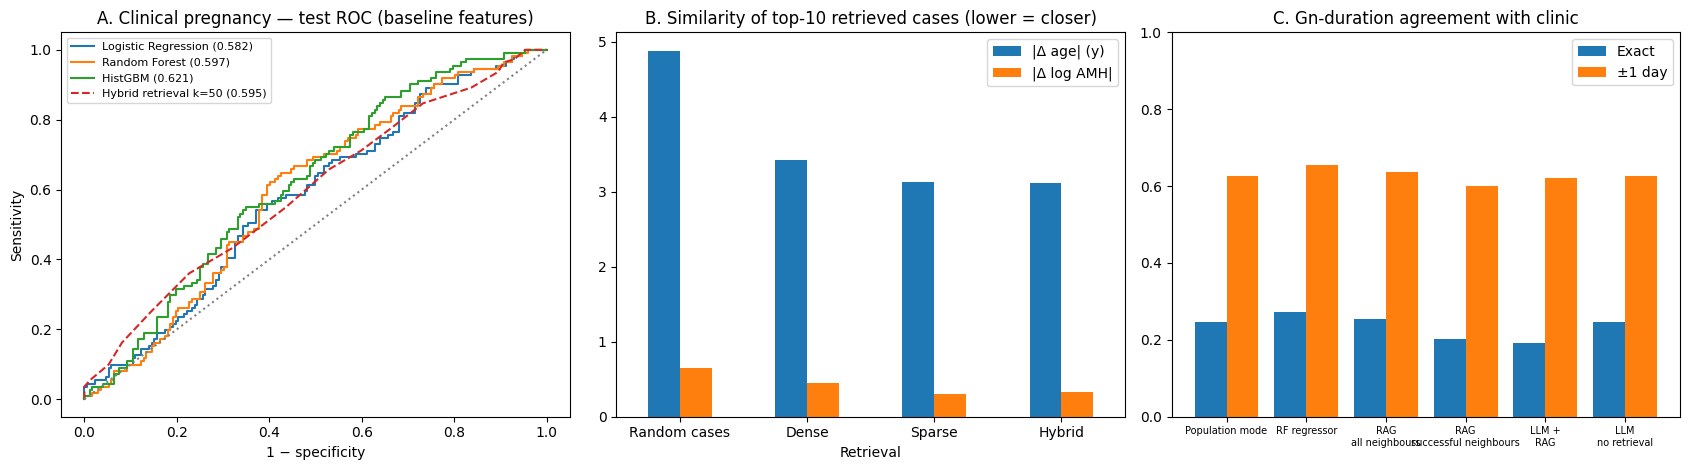

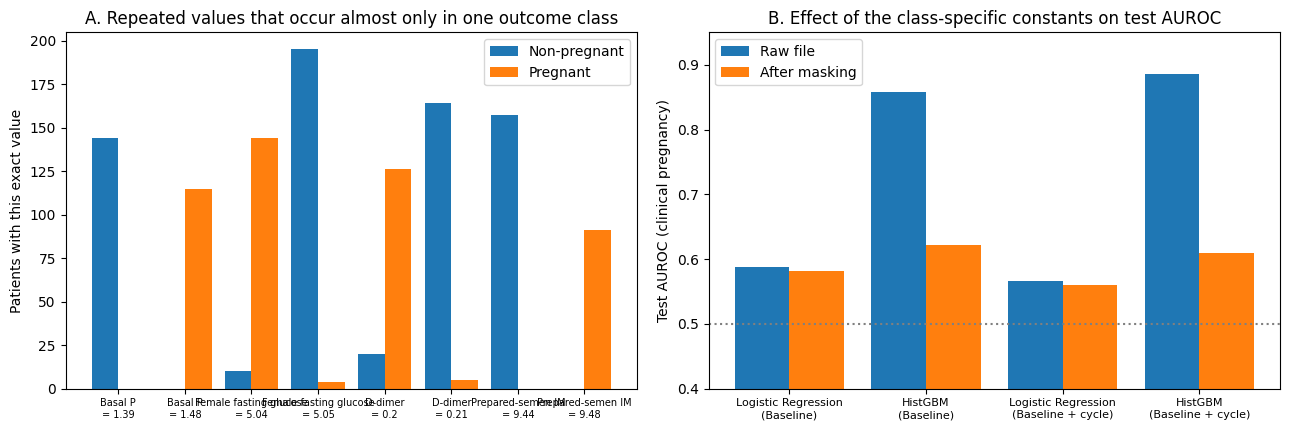

{
  "dataset": "Wang M. (2026) Embryo dataset, Mendeley Data v1, doi:10.17632/x5s3ky9cpv.1",
  "n_embryo_rows": 2542,
  "n_patients": 1415,
  "n_train": 1132,
  "n_test": 283,
  "pregnancy_rate": 0.392226148409894,
  "implausible_values_cleaned": 360,
  "best_baseline_model": "HistGBM",
  "best_baseline_test_auroc": 0.6214,
  "best_baseline_ci": "[0.558, 0.684]",
  "class_constants": {
    "n_values": 25,
    "n_columns": 13,
    "n_cells_masked": 2382,
    "n_patients_affected": 836
  },
  "leakage_effect": [
    {
      "Features": "Baseline",
      "Model": "Logistic Regression",
      "AUROC raw file (leaky)": 0.5883,
      "AUROC after masking": 0.5823
    },
    {
      "Features": "Baseline",
      "Model": "HistGBM",
      "AUROC raw file (leaky)": 0.8579,
      "AUROC after masking": 0.6214
    },
    {
      "Features": "Baseline + cycle",
      "Model": "Logistic Regression",
      "AUROC raw file (leaky)": 0.5664,
      "AUROC after masking": 0.5605
    },
    {
      "Feat

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
for (fs, m), p in test_probs.items():
    if fs == 'Baseline':
        f, t, _ = roc_curve(y_te, p); ax.plot(f, t, label=f'{m} ({roc_auc_score(y_te, p):.3f})')
f, t, _ = roc_curve(y_te, ret_probs['hybrid']); ax.plot(f, t, '--', label=f'Hybrid retrieval k={TOP_K_OUTCOME} ({roc_auc_score(y_te, ret_probs["hybrid"]):.3f})')
ax.plot([0, 1], [0, 1], ':', color='grey'); ax.set_title('A. Clinical pregnancy — test ROC (baseline features)')
ax.set_xlabel('1 − specificity'); ax.set_ylabel('Sensitivity'); ax.legend(fontsize=8)

ax = axes[1]
sub = tbl_ret.set_index('Retrieval')[['|Δ age| (y)', '|Δ log AMH|']]
sub.plot.bar(ax=ax, rot=0); ax.set_title(f'B. Similarity of top-{TOP_K} retrieved cases (lower = closer)')

ax = axes[2]
plot_recs = dict(recs)
if len(llm_log):
    for cond, (idx, rec) in LLM_RECS.items():
        full = np.full(len(test), np.nan); full[idx] = rec; plot_recs[cond] = full
w1 = [np.nan_to_num(np.abs(r - gn_te) <= 1).mean() for r in plot_recs.values()]
ex = [np.nan_to_num(r == gn_te).mean() for r in plot_recs.values()]
x = np.arange(len(plot_recs)); ax.bar(x - 0.2, ex, 0.4, label='Exact'); ax.bar(x + 0.2, w1, 0.4, label='±1 day')
ax.set_xticks(x); ax.set_xticklabels([n.replace(' (baseline features)', '').replace(' – ', '\n').replace(', ', '\n').replace(' + ', ' +\n') for n in plot_recs], fontsize=7)
ax.set_ylim(0, 1); ax.set_title('C. Gn-duration agreement with clinic'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/genivf_v8_dashboard.png', dpi=200); plt.show()

# ── Leakage figure ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
show = ['f_basal_p', 'f_glucose', 'f_d_dimer', 'm_post_im']
labels_show = {'f_basal_p': 'Basal P', 'f_glucose': 'Female fasting glucose', 'f_d_dimer': 'D-dimer', 'm_post_im': 'Prepared-semen IM'}
xt, n0s, n1s = [], [], []
for c in show:
    for _, r in CLASS_CONSTANTS[CLASS_CONSTANTS.column == c].iterrows():
        m = np.isclose(df[c], r.value)
        n0s.append(int((m & (df[TARGET] == 0)).sum())); n1s.append(int((m & (df[TARGET] == 1)).sum()))
        xt.append(f"{labels_show[c]}\n= {r.value:g}")
x = np.arange(len(xt))
ax.bar(x - 0.2, n0s, 0.4, label='Non-pregnant'); ax.bar(x + 0.2, n1s, 0.4, label='Pregnant')
ax.set_xticks(x); ax.set_xticklabels(xt, fontsize=7); ax.set_ylabel('Patients with this exact value')
ax.set_title('A. Repeated values that occur almost only in one outcome class'); ax.legend()
ax = axes[1]
lab = [f"{r.Model}\n({r.Features})" for r in tbl_leak.itertuples()]
x = np.arange(len(lab))
ax.bar(x - 0.2, tbl_leak['AUROC raw file (leaky)'], 0.4, label='Raw file'); ax.bar(x + 0.2, tbl_leak['AUROC after masking'], 0.4, label='After masking')
ax.axhline(0.5, ls=':', c='grey'); ax.set_ylim(0.4, 0.95); ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=8)
ax.set_ylabel('Test AUROC (clinical pregnancy)'); ax.set_title('B. Effect of the class-specific constants on test AUROC'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/genivf_v8_leakage.png', dpi=200); plt.show()

best = tbl_ml[tbl_ml.Features == 'Baseline'].sort_values('Test AUROC', ascending=False).iloc[0]
summary = {
    'dataset': 'Wang M. (2026) Embryo dataset, Mendeley Data v1, doi:10.17632/x5s3ky9cpv.1',
    'n_embryo_rows': int(len(emb)), 'n_patients': int(len(df)), 'n_train': int(len(train)), 'n_test': int(len(test)),
    'pregnancy_rate': float(df.pregnancy.mean()),
    'implausible_values_cleaned': int(sum(cleaned.values())),
    'best_baseline_model': best.Model, 'best_baseline_test_auroc': float(best['Test AUROC']), 'best_baseline_ci': best['95% CI'],
    'class_constants': {'n_values': int(len(CLASS_CONSTANTS)), 'n_columns': int(CLASS_CONSTANTS.column.nunique()),
                        'n_cells_masked': n_masked, 'n_patients_affected': n_pt_affected},
    'leakage_effect': tbl_leak.to_dict(orient='records'),
    'label_sorted_file': bool((df.sort_values('patient_id')[TARGET].diff().fillna(0) >= 0).all()),
    'retrieval_k_outcome': int(TOP_K_OUTCOME), 'retrieval_k_context': int(TOP_K),
    'retrieval_k_selection_train_cv': {int(k): float(v) for k, v in k_sel.items()},
    'retrieval_outcome_auroc': {m: float(roc_auc_score(y_te, p)) for m, p in ret_probs.items()},
    'gn_days_exact': {n: float((r == gn_te).mean()) for n, r in recs.items()},
    'gn_days_within1': {n: float((np.abs(r - gn_te) <= 1).mean()) for n, r in recs.items()},
    'exploratory_concordance': {k: (float(v) if np.isscalar(v) else [float(x) for x in v]) for k, v in EXPLORATORY.items()},
    'llm_step_run': bool(len(llm_log)),
}
if len(llm_log):
    summary['llm'] = {'provider': LLM_PROVIDER, 'model': LLM_MODEL, 'rationale_check': RATIONALE_CHECK,
                      'returned_models': llm_log.returned_model.unique().tolist(),
                      'table': tbl_llm.to_dict(orient='records'), 'mcnemar_exact': MCNEMAR}
    if '11434' in LLM_BASE_URL:   # Ollama: record the exact model build
        import urllib.request
        _req = urllib.request.Request(LLM_BASE_URL.replace('/v1', '') + '/api/show', data=json.dumps({'model': LLM_MODEL}).encode(),
                                      headers={'Content-Type': 'application/json'})
        _det = json.load(urllib.request.urlopen(_req, timeout=30)).get('details', {})
        summary['llm'].update({'quantization': _det.get('quantization_level'), 'parameter_size': _det.get('parameter_size'),
                               'family': _det.get('family')})
with open(f'{OUTPUT_DIR}/summary_metrics_v8.json', 'w') as fh:
    json.dump(summary, fh, indent=2)
print(json.dumps(summary, indent=2))

## ✅ Reporting rules for the paper
1. Every number in the manuscript must appear in an output of this notebook (or `summary_metrics_v8.json`).
2. Report **clinical pregnancy**, not live birth; **1,415 patients** (2,542 embryo records), not 2,542 cycles.
3. Do not report expert ratings, RAGAS scores, clinician satisfaction, DAS, OHSS, or protocol accuracy for dose/trigger/protocol type — none are measurable on this dataset.
4. LLM results only if Step 9 ran with a real model and **zero** failed calls.